# 05 - p5986 full-feature XGBoost for TTF and shear stress

This notebook rebuilds the machine-learning workflow from the raw p5986
passive-acoustic files
- moving window length = about 5% of the mean laboratory seismic cycle;
- 90% overlap between consecutive windows;
- two contiguous, non-overlapping subwindows per current window;
- feature families: raw moments 1-4, variance, skewness, kurtosis,
  threshold precursor statistics, Fourier-band power, current window `N`, and previous non-overlapping window `N-10` are also retained for RFE;
- recursive feature elimination (RFE), XGBoost, five-fold
  cross-validation, and Bayesian hyperparameter optimization;
- first contiguous 80% of the database for training and the second
  contiguous 20% for testing;
- shear-stress label = mean stress in the same current acoustic window;
- TTF label = time remaining from the window centre to the next
  shear-stress failure pick.

References:

- Hulbert et al. (2019), *Similarity of fast and slow earthquakes
  illuminated by machine learning*, Nature Geoscience 12, 69-74.
- Supplementary Information for Hulbert et al. (2019).


In [ ]:
# 1. Common setup
from pathlib import Path
import json
import math
import os
import re
import shutil
import subprocess
import sys
import time
import warnings

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as exc:
    print('Not running in Colab or Drive already mounted:', exc)

P5986_ROOT = Path(os.environ.get(
    'P5986_ROOT',
    '/content/drive/MyDrive/MLStressDrop/p5986',
))
assert P5986_ROOT.exists(), (
    f'Cannot find p5986 folder: {P5986_ROOT}. '
    'Add a Drive shortcut or edit P5986_ROOT.'
)

AC_DIR = P5986_ROOT / 'acData'
RUN1_DIR = AC_DIR / 'run1'
MAT_DIR = AC_DIR / 'MatFiles'
OUT_DIR = P5986_ROOT / 'colab_outputs_p5986'
OUT_DIR.mkdir(exist_ok=True, parents=True)

print('P5986_ROOT =', P5986_ROOT)
print('OUT_DIR    =', OUT_DIR)


Mounted at /content/drive
P5986_ROOT = /content/drive/MyDrive/MLStressDrop/p5986
OUT_DIR    = /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986


In [ ]:
# 2. Install the model-selection packages used below.
subprocess.check_call([
    sys.executable,
    '-m',
    'pip',
    'install',
    '-q',
    'xgboost',
    'scikit-optimize',
])


0

## 1. File and MATLAB helpers

p5986 stores 12 channels interleaved in each `WF_*.ac` file. The reader
below reproduces the verified layout used in Notebook 04, but reads only
the selected sensor. Physical time is never constructed from an integer
gap: `acTime` supplies every waveform start and `ts_adjusted` supplies the
within-waveform sample spacing.


In [ ]:
def scalar(x, default=None):
    if x is None:
        return default
    arr = np.asarray(x)
    if arr.size == 0:
        return default
    try:
        return arr.item()
    except Exception:
        return arr.ravel()[0]


def text_scalar(x):
    if x is None:
        return None
    if isinstance(x, str):
        return x.strip()
    arr = np.asarray(x)
    if arr.size == 0:
        return None
    if arr.dtype.kind in {'U', 'S'}:
        return ''.join(arr.astype(str).ravel()).strip()
    return str(arr.ravel()[0]).strip()


def loadmat_any(path):
    path = Path(path)
    try:
        return {
            k: v
            for k, v in sio.loadmat(
                path,
                squeeze_me=True,
                struct_as_record=False,
            ).items()
            if not k.startswith('__')
        }
    except NotImplementedError:
        out = {}
        with h5py.File(path, 'r') as f:
            def walk(group, prefix=''):
                for key, obj in group.items():
                    name = f'{prefix}/{key}' if prefix else key
                    if isinstance(obj, h5py.Dataset):
                        out[name] = obj[()]
                    else:
                        walk(obj, name)
            walk(f)
        return out


def sorted_wf_files(run_dir):
    files = list(Path(run_dir).glob('WF_*.ac'))

    def number(path):
        match = re.fullmatch(r'WF_(\d+)\.ac', path.name)
        return int(match.group(1)) if match else 10**18

    return sorted(files, key=number)


def wf_number(path):
    match = re.fullmatch(r'WF_(\d+)\.ac', Path(path).name)
    if match is None:
        raise ValueError(f'Invalid acoustic filename: {Path(path).name}')
    return int(match.group(1))


## 2. Acoustic settings and synchronization validation


In [ ]:
AC_SETTINGS_FILE = MAT_DIR / 'p5986_run1.mat'
SYNC_FILE = AC_DIR / 'p5986_sync_run1.mat'
SYNC_CONVERTED_FILE = AC_DIR / 'p5986_sync_run1_converted.mat'

assert AC_SETTINGS_FILE.exists(), AC_SETTINGS_FILE
assert SYNC_FILE.exists() or SYNC_CONVERTED_FILE.exists()

settings = loadmat_any(AC_SETTINGS_FILE)

Nsamples = int(scalar(settings.get('Nsamples')))
Ngap0 = int(scalar(settings.get('Ngap')))
numAcqs = int(scalar(settings.get('numAcqs')))
numFrames = int(scalar(settings.get('numFrames')))
channels2save = np.asarray(
    settings.get('channels2save'),
    dtype=int,
).ravel()
samplingFreq_MHz = float(scalar(settings.get('samplingFreq')))
Decimation = int(scalar(settings.get('Decimation'), 1) or 1)

numCH = len(channels2save)
numSFpfile = numFrames // 2
numWFpSFpCH = numAcqs
numWFpfilepCH = numSFpfile * numWFpSFpCH
points_per_sf_per_ch = numWFpSFpCH * Nsamples
fs_ac_nominal = samplingFreq_MHz * 1e6 / Decimation

assert Nsamples > 0
assert numFrames % 2 == 0
assert numCH == 12

print({
    'Nsamples': Nsamples,
    'Ngap_nominal': Ngap0,
    'waveforms_per_file_per_channel': numWFpfilepCH,
    'channels2save': channels2save.tolist(),
    'fs_ac_nominal_hz': fs_ac_nominal,
})


{'Nsamples': 512, 'Ngap_nominal': 100, 'waveforms_per_file_per_channel': 5120, 'channels2save': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], 'fs_ac_nominal_hz': 2500000.0}


In [ ]:
SYNC_WANTED_KEYS = [
    'runname',
    'acousticrun',
    'AcSettingsfile',
    'WF_path',
    'totalnumberoffiles',
    'acTime',
    'ts',
    'ts_adjusted',
]


def load_sync_minimal(path):
    path = Path(path)
    try:
        raw = sio.loadmat(
            path,
            variable_names=SYNC_WANTED_KEYS,
            squeeze_me=True,
            struct_as_record=False,
        )
        return {
            k: v
            for k, v in raw.items()
            if not k.startswith('__')
        }
    except NotImplementedError:
        full = loadmat_any(path)
        return {
            key: full[key]
            for key in SYNC_WANTED_KEYS
            if key in full
        }


sync = {}
sync_path_used = None
load_errors = []

for candidate in [SYNC_FILE, SYNC_CONVERTED_FILE]:
    if not candidate.exists():
        continue
    try:
        candidate_sync = load_sync_minimal(candidate)
        if 'acTime' not in candidate_sync:
            raise KeyError('acTime is missing')
        if (
            'ts' not in candidate_sync
            and 'ts_adjusted' not in candidate_sync
        ):
            raise KeyError('neither ts nor ts_adjusted is present')
        sync = candidate_sync
        sync_path_used = candidate
        break
    except Exception as exc:
        load_errors.append(
            f'{candidate}: {type(exc).__name__}: {exc}'
        )

if not sync:
    raise RuntimeError(
        'No valid synchronization file was loaded.\n'
        + '\n'.join(load_errors)
    )

assert text_scalar(sync.get('runname')) == 'p5986'
assert text_scalar(sync.get('acousticrun')) == 'run1'

ts_key = 'ts' if 'ts' in sync else 'ts_adjusted'
ts_raw = float(scalar(sync[ts_key]))
nominal_ts_s = 1.0 / fs_ac_nominal
ts_candidates = {
    'seconds/sample': ts_raw,
    'microseconds/sample': ts_raw * 1e-6,
}
ts_unit, ts = min(
    ts_candidates.items(),
    key=lambda item: abs(item[1] - nominal_ts_s),
)
if not np.isfinite(ts) or ts <= 0:
    raise ValueError(f'Invalid sample interval: {ts}')
if abs(ts - nominal_ts_s) / nominal_ts_s > 0.01:
    raise ValueError('Sync sample interval disagrees with settings.')

fs_ac_adjusted = 1.0 / ts
acTime = np.asarray(sync['acTime'], dtype=np.float64).ravel()
if len(acTime) < 2 or not np.all(np.isfinite(acTime)):
    raise ValueError('Invalid acTime array.')
if not np.all(np.diff(acTime) > 0):
    raise ValueError('acTime must be strictly increasing.')

wf_files = sorted_wf_files(RUN1_DIR)
actual_nfiles = len(wf_files)
if actual_nfiles == 0:
    raise FileNotFoundError(f'No WF_*.ac files in {RUN1_DIR}')

nfiles_from_time, remainder = divmod(
    len(acTime),
    numWFpfilepCH,
)
if remainder != 0 or nfiles_from_time != actual_nfiles:
    raise ValueError(
        'acTime length and actual WF-file count disagree: '
        f'{len(acTime)=}, {actual_nfiles=}, '
        f'{numWFpfilepCH=}'
    )

expected_numbers = list(range(1, actual_nfiles + 1))
actual_numbers = [wf_number(path) for path in wf_files]
if actual_numbers != expected_numbers:
    raise ValueError('WF file numbering is not continuous.')

sync_nfiles = actual_nfiles
print('Loaded sync:', sync_path_used)
print('ts source/unit:', ts_key, ts_unit)
print('adjusted acoustic fs:', fs_ac_adjusted, 'Hz')
print('WF files:', sync_nfiles)
print('acTime range:', (acTime[0], acTime[-1]))


Loaded sync: /content/drive/MyDrive/MLStressDrop/p5986/acData/p5986_sync_run1.mat
ts source/unit: ts_adjusted microseconds/sample
adjusted acoustic fs: 2499611.5165609503 Hz
WF files: 2922
acTime range: (np.float64(1075.1080783952384), np.float64(4741.034294044663))


## 3. Load the Notebook 03 failure picks and label source

In [ ]:
EVENTS_CSV = OUT_DIR / '03_failure_picks_p5986_run1.csv'
LABELS_H5 = (
    OUT_DIR
    / '03_mechanical_labels_TTF_shear_stress_p5986_run1.h5'
)

assert EVENTS_CSV.exists(), EVENTS_CSV
assert LABELS_H5.exists(), LABELS_H5

events = pd.read_csv(EVENTS_CSV)
required_event_columns = {
    'failure_time_s',
    'cycle_duration_to_next_failure_s',
}
missing = required_event_columns.difference(events.columns)
if missing:
    raise KeyError(f'Missing event columns: {sorted(missing)}')

with h5py.File(LABELS_H5, 'r') as f:
    mechanical_time_s = np.asarray(
        f['time_s'][:],
        dtype=np.float64,
    )
    mechanical_shear_stress_mpa = np.asarray(
        f['shear_stress_mpa'][:],
        dtype=np.float64,
    )

if not np.all(np.diff(mechanical_time_s) > 0):
    raise ValueError('Mechanical time must be strictly increasing.')

failure_times = (
    events['failure_time_s']
    .to_numpy(dtype=np.float64)
)
if not np.all(np.diff(failure_times) > 0):
    raise ValueError('Failure picks must be strictly increasing.')

cycle_duration = events[
    'cycle_duration_to_next_failure_s'
].to_numpy(dtype=np.float64)
valid_cycles = cycle_duration[
    np.isfinite(cycle_duration) & (cycle_duration > 0)
]
if len(valid_cycles) < 5:
    raise ValueError('Too few valid cycles for window selection.')

mean_cycle_s = float(np.mean(valid_cycles))
median_cycle_s = float(np.median(valid_cycles))

WINDOW_SECONDS_OVERRIDE = None
WINDOW_SECONDS = (
    0.05 * mean_cycle_s
    if WINDOW_SECONDS_OVERRIDE is None
    else float(WINDOW_SECONDS_OVERRIDE)
)
WINDOW_SECONDS = max(round(WINDOW_SECONDS, 3), 0.005)
STEP_SECONDS = 0.10 * WINDOW_SECONDS
HALF_WINDOW_SECONDS = 0.5 * WINDOW_SECONDS

analysis_start_s = float(mechanical_time_s[0])
analysis_end_s = float(mechanical_time_s[-1])

print('analysis interval:', (analysis_start_s, analysis_end_s))
print('failure picks:', len(failure_times))
print('mean / median cycle:', mean_cycle_s, median_cycle_s)
print('window / step:', WINDOW_SECONDS, STEP_SECONDS)


analysis interval: (2310.00000001185, 3159.9990001850174)
failure picks: 310
mean / median cycle: 2.7418284795229853 2.7170000005535258
window / step: 0.137 0.013700000000000002


## 4. One-sensor waveform reader

The default is Python sensor index 9, which is Verasonics hardware
channel 10 in the saved p5986 settings. Change only
`SENSOR_ZERO_BASED` for a sensor comparison.


In [ ]:
SENSOR_ZERO_BASED = 9

if not 0 <= SENSOR_ZERO_BASED < numCH:
    raise IndexError(
        f'SENSOR_ZERO_BASED must be in 0..{numCH - 1}'
    )


def read_one_sensor_waveforms_fast(path, sensor_zero_based):
    path = Path(path)
    sensor = int(sensor_zero_based)
    expected_bytes = (
        points_per_sf_per_ch
        * numCH
        * numSFpfile
        * np.dtype('<i2').itemsize
    )
    if path.stat().st_size != expected_bytes:
        raise ValueError(
            f'{path.name}: file size mismatch; '
            f'found={path.stat().st_size}, '
            f'expected={expected_bytes}'
        )

    out = np.empty(
        (numSFpfile, numWFpSFpCH, Nsamples),
        dtype=np.int16,
    )
    with open(path, 'rb') as stream:
        for superframe in range(numSFpfile):
            value_offset = (
                (superframe * numCH + sensor)
                * points_per_sf_per_ch
            )
            stream.seek(
                value_offset * np.dtype('<i2').itemsize
            )
            block = np.fromfile(
                stream,
                dtype='<i2',
                count=points_per_sf_per_ch,
            )
            if block.size != points_per_sf_per_ch:
                raise ValueError(
                    f'{path.name}: incomplete superframe '
                    f'{superframe}'
                )
            out[superframe] = block.reshape(
                numWFpSFpCH,
                Nsamples,
            )
    return out.reshape(-1, Nsamples)


test_waveforms = read_one_sensor_waveforms_fast(
    wf_files[0],
    SENSOR_ZERO_BASED,
)
assert test_waveforms.shape == (numWFpfilepCH, Nsamples)
print('reader test:', wf_files[0].name, test_waveforms.shape)
del test_waveforms


reader test: WF_1.ac (5120, 512)


## 5. Full feature families


In [ ]:
# Paper-specified structure.
FEATURE_CONTEXTS = {
    'half1': 'first contiguous half of current window',
    'half2': 'second contiguous half of current window',
    'N': 'full current window',
    'N_minus_10': 'previous adjacent non-overlapping window',
}

# Not numerically specified in the paper: record these adaptations.
THRESHOLD_SIGMA_MULTIPLIERS = np.array(
    [3.0, 5.0, 10.0, 20.0, 30.0, 40.0, 50.0],
    dtype=np.float64,
)
REQUESTED_FREQUENCY_BANDS_HZ = [
    (0.0, 20_000.0),
    (20_000.0, 50_000.0),
    (50_000.0, 100_000.0),
    (100_000.0, 200_000.0),
    (200_000.0, 400_000.0),
    (400_000.0, 800_000.0),
    (800_000.0, 1_250_000.0),
]
MIN_COVERAGE_FRACTION = 0.75
CALIBRATION_MAX_FILES = 5
CALIBRATION_SAMPLE_STRIDE = 8

nyquist_hz = 0.5 * fs_ac_adjusted
frequency_bands_hz = []
for low_hz, high_hz in REQUESTED_FREQUENCY_BANDS_HZ:
    low = max(0.0, float(low_hz))
    high = min(float(high_hz), nyquist_hz)
    if high > low:
        frequency_bands_hz.append((low, high))

print('threshold sigma multiples:', THRESHOLD_SIGMA_MULTIPLIERS)
print('usable frequency bands (Hz):', frequency_bands_hz)
print('p5986 Nyquist (Hz):', nyquist_hz)


threshold sigma multiples: [ 3.  5. 10. 20. 30. 40. 50.]
usable frequency bands (Hz): [(0.0, 20000.0), (20000.0, 50000.0), (50000.0, 100000.0), (100000.0, 200000.0), (200000.0, 400000.0), (400000.0, 800000.0), (800000.0, 1249805.7582804752)]
p5986 Nyquist (Hz): 1249805.7582804752


## 6. Select the raw files and calibrate precursor thresholds from training time only


In [ ]:
# The previous N-10 context needs one additional full window.
acoustic_read_start_s = analysis_start_s - WINDOW_SECONDS
acoustic_read_end_s = analysis_end_s + WINDOW_SECONDS

file_first_acq = (
    np.arange(sync_nfiles, dtype=np.int64)
    * numWFpfilepCH
)
file_last_acq = file_first_acq + numWFpfilepCH - 1
file_start_s = acTime[file_first_acq]
file_end_s = (
    acTime[file_last_acq]
    + (Nsamples - 1) * ts
)

overlaps = (
    (file_end_s >= acoustic_read_start_s)
    & (file_start_s <= acoustic_read_end_s)
)
selected_file_indices = np.flatnonzero(overlaps)
selected_files = [
    wf_files[int(index)]
    for index in selected_file_indices
]
if not selected_files:
    raise ValueError('No WF files overlap the analysis interval.')

# Threshold calibration is restricted to the early training half to avoid test information.
nominal_split_time_s = 0.5 * (
    analysis_start_s + analysis_end_s
)
calibration_candidates = [
    path
    for path in selected_files
    if file_start_s[wf_number(path) - 1] < nominal_split_time_s
][:CALIBRATION_MAX_FILES]
if not calibration_candidates:
    raise ValueError('No training-half files for calibration.')

calibration_samples = []
for path in calibration_candidates:
    waveform = read_one_sensor_waveforms_fast(
        path,
        SENSOR_ZERO_BASED,
    )
    calibration_samples.append(
        waveform[:, ::CALIBRATION_SAMPLE_STRIDE]
        .reshape(-1)
        .astype(np.float64)
    )
    del waveform

calibration_samples = np.concatenate(calibration_samples)
robust_center = float(np.median(calibration_samples))
robust_mad = float(np.median(
    np.abs(calibration_samples - robust_center)
))
robust_sigma = 1.4826 * robust_mad
if not np.isfinite(robust_sigma) or robust_sigma <= 0:
    robust_sigma = float(np.std(calibration_samples, ddof=0))
if not np.isfinite(robust_sigma) or robust_sigma <= 0:
    raise ValueError('Could not estimate a positive noise scale.')

amplitude_thresholds = (
    THRESHOLD_SIGMA_MULTIPLIERS * robust_sigma
)
del calibration_samples

print(
    'selected files:',
    len(selected_files),
    selected_files[0].name,
    'to',
    selected_files[-1].name,
)
print('calibration files:', [p.name for p in calibration_candidates])
print('robust centre / sigma:', robust_center, robust_sigma)
print('absolute-deviation thresholds:', amplitude_thresholds)


selected files: 678 WF_985.ac to WF_1662.ac
calibration files: ['WF_985.ac', 'WF_986.ac', 'WF_987.ac', 'WF_988.ac', 'WF_989.ac']
robust centre / sigma: 4.0 2.9652
absolute-deviation thresholds: [  8.8956  14.826   29.652   59.304   88.956  118.608  148.26  ]


## 7. Waveform-level sufficient statistics

Raw powers up to order four and threshold exceedance counts aggregate
exactly over the observed samples. Spectral power is calculated for each
stored 512-sample waveform and then averaged within a time interval.
Because p5986 contains acquisition gaps, this avoids pretending that
samples on opposite sides of a gap are contiguous. It is the required
gap-aware adaptation of the paper's continuous-record Fourier features.


In [ ]:
rfft_frequency_hz = np.fft.rfftfreq(Nsamples, d=ts)
frequency_bin_hz = float(rfft_frequency_hz[1] - rfft_frequency_hz[0])
hann_window = np.hanning(Nsamples).astype(np.float32)
hann_energy = float(np.sum(hann_window ** 2, dtype=np.float64))

band_masks = []
band_names = []
for low_hz, high_hz in frequency_bands_hz:
    # Include the right edge only for the last band.
    if high_hz >= nyquist_hz:
        mask = (
            (rfft_frequency_hz >= low_hz)
            & (rfft_frequency_hz <= high_hz)
        )
    else:
        mask = (
            (rfft_frequency_hz >= low_hz)
            & (rfft_frequency_hz < high_hz)
        )
    if not np.any(mask):
        raise ValueError(
            f'No FFT bins in band {(low_hz, high_hz)}'
        )
    band_masks.append(mask)
    band_names.append(
        f'bandpower_{int(low_hz)}_{int(high_hz)}hz'
    )

ps20_index = int(np.argmin(
    np.abs(rfft_frequency_hz - 20_000.0)
))
ps20_actual_hz = float(rfft_frequency_hz[ps20_index])

base_stat_names = [
    'sample_count',
    'sum_x1',
    'sum_x2',
    'sum_x3',
    'sum_x4',
]
threshold_stat_names = [
    f'threshold_count_{value:g}sigma'
    for value in THRESHOLD_SIGMA_MULTIPLIERS
]
spectral_stat_names = ['psd_20khz'] + band_names
sufficient_stat_names = (
    base_stat_names
    + threshold_stat_names
    + spectral_stat_names
)


def waveform_sufficient_statistics(waveforms):
    y = np.asarray(waveforms, dtype=np.float64)
    if y.ndim != 2 or y.shape[1] != Nsamples:
        raise ValueError(
            f'Expected [n_waveforms, {Nsamples}] array.'
        )

    n_waveforms = len(y)
    stats = np.empty(
        (n_waveforms, len(sufficient_stat_names)),
        dtype=np.float64,
    )
    stats[:, 0] = Nsamples
    stats[:, 1] = np.sum(y, axis=1, dtype=np.float64)
    y2 = y * y
    stats[:, 2] = np.sum(y2, axis=1, dtype=np.float64)
    stats[:, 3] = np.sum(y2 * y, axis=1, dtype=np.float64)
    stats[:, 4] = np.sum(y2 * y2, axis=1, dtype=np.float64)

    absolute_deviation = np.abs(y - robust_center)
    cursor = len(base_stat_names)
    for threshold in amplitude_thresholds:
        stats[:, cursor] = np.sum(
            absolute_deviation >= threshold,
            axis=1,
            dtype=np.int32,
        )
        cursor += 1

    demeaned = y - np.mean(y, axis=1, keepdims=True)
    spectrum = np.fft.rfft(
        demeaned * hann_window,
        axis=1,
    )
    psd = (np.abs(spectrum) ** 2) / (
        fs_ac_adjusted * hann_energy
    )
    if Nsamples % 2 == 0:
        psd[:, 1:-1] *= 2.0
    else:
        psd[:, 1:] *= 2.0

    stats[:, cursor] = psd[:, ps20_index]
    cursor += 1
    for mask in band_masks:
        stats[:, cursor] = (
            np.sum(psd[:, mask], axis=1)
            * frequency_bin_hz
        )
        cursor += 1

    return stats


print('20 kHz PSD bin is', ps20_actual_hz, 'Hz')
print('sufficient statistics per waveform:', len(sufficient_stat_names))


20 kHz PSD bin is 19528.214973132424 Hz
sufficient statistics per waveform: 20


In [ ]:
# Unit test the moment and threshold aggregations before the long scan.
rng = np.random.default_rng(123)
synthetic = rng.integers(
    -20,
    21,
    size=(7, Nsamples),
    dtype=np.int16,
)
synthetic_stats = waveform_sufficient_statistics(synthetic)

flattened = synthetic.astype(np.float64).ravel()
assert np.isclose(
    synthetic_stats[:, 1].sum() / flattened.size,
    np.mean(flattened),
)
assert np.isclose(
    synthetic_stats[:, 2].sum() / flattened.size,
    np.mean(flattened ** 2),
)
assert np.isclose(
    synthetic_stats[:, 3].sum() / flattened.size,
    np.mean(flattened ** 3),
)
assert np.isclose(
    synthetic_stats[:, 4].sum() / flattened.size,
    np.mean(flattened ** 4),
)

first_threshold_count = np.sum(
    np.abs(flattened - robust_center)
    >= amplitude_thresholds[0]
)
assert synthetic_stats[:, 5].sum() == first_threshold_count
assert np.isfinite(synthetic_stats).all()
print('synthetic sufficient-statistics tests passed')


synthetic sufficient-statistics tests passed


## 8. Scan the selected p5986 files

This is the expensive cell. On the same Drive configuration used for
Notebook 04, raw reads alone took roughly 25 minutes for 678 files;
calculating FFT features adds runtime. The cell keeps one file of raw
samples in memory at a time.


In [ ]:
# load checkpoint
# ============================================================
# Load Section 8 checkpoint when its settings are still valid
# ============================================================

CHECKPOINT_SCHEMA_VERSION = 1
CHECKPOINT_DIR = OUT_DIR / 'checkpoints'
CHECKPOINT_FILE = CHECKPOINT_DIR / (
    f'06_section8_scan_p5986_run1_sensor{SENSOR_ZERO_BASED}.h5'
)

# These settings must exactly match the settings used when saving.
section8_signature = {
    'schema_version': CHECKPOINT_SCHEMA_VERSION,
    'experiment': 'p5986',
    'run': 'run1',
    'sensor_zero_based': int(SENSOR_ZERO_BASED),
    'hardware_channel': int(channels2save[SENSOR_ZERO_BASED]),
    'selected_file_numbers': [
        int(wf_number(path))
        for path in selected_files
    ],
    'Nsamples': int(Nsamples),
    'numWFpfilepCH': int(numWFpfilepCH),
    'ts_s': float(ts),
    'acTime_length': int(len(acTime)),
    'acTime_first_s': float(acTime[0]),
    'acTime_last_s': float(acTime[-1]),
    'analysis_start_s': float(analysis_start_s),
    'analysis_end_s': float(analysis_end_s),
    'acoustic_read_start_s': float(acoustic_read_start_s),
    'acoustic_read_end_s': float(acoustic_read_end_s),
    'sufficient_stat_names': list(sufficient_stat_names),
    'robust_center_adc': float(robust_center),
    'robust_sigma_adc': float(robust_sigma),
    'amplitude_thresholds_adc': [
        float(value)
        for value in amplitude_thresholds
    ],
    'frequency_bands_hz': [
        [float(low), float(high)]
        for low, high in frequency_bands_hz
    ],
    'ps20_actual_fft_bin_hz': float(ps20_actual_hz),
}

section8_signature_json = json.dumps(
    section8_signature,
    sort_keys=True,
    separators=(',', ':'),
    allow_nan=False,
)

checkpoint_loaded = False

if CHECKPOINT_FILE.exists():
    try:
        with h5py.File(CHECKPOINT_FILE, 'r') as checkpoint:
            if not bool(checkpoint.attrs.get('complete', False)):
                raise ValueError(
                    'Checkpoint is not marked complete.'
                )

            saved_signature = checkpoint.attrs.get(
                'signature_json',
                '',
            )

            if isinstance(saved_signature, bytes):
                saved_signature = saved_signature.decode('utf-8')

            if saved_signature != section8_signature_json:
                raise ValueError(
                    'Checkpoint settings do not match the current '
                    'Notebook 06 settings.'
                )

            required_datasets = {
                'waveform_time_s',
                'waveform_file_number',
                'cumulative_statistics',
            }

            missing = required_datasets.difference(
                checkpoint.keys()
            )

            if missing:
                raise KeyError(
                    f'Missing checkpoint datasets: {sorted(missing)}'
                )

            loaded_time = checkpoint['waveform_time_s'][:]
            loaded_file_number = checkpoint[
                'waveform_file_number'
            ][:]
            loaded_cumulative = checkpoint[
                'cumulative_statistics'
            ][:]

        # Validate without reading the WF_*.ac raw files.
        expected_count = 0
        expected_file_numbers = []

        for path in selected_files:
            file_number = wf_number(path)

            first_acq = (
                (file_number - 1) * numWFpfilepCH
            )
            last_acq = first_acq + numWFpfilepCH

            starts = acTime[first_acq:last_acq]
            centres = (
                starts
                + 0.5 * (Nsamples - 1) * ts
            )

            keep = (
                (centres >= acoustic_read_start_s)
                & (centres <= acoustic_read_end_s)
            )

            kept_count = int(np.count_nonzero(keep))
            expected_count += kept_count

            if kept_count > 0:
                expected_file_numbers.append(file_number)

        assert len(loaded_time) == expected_count
        assert len(loaded_file_number) == expected_count

        assert loaded_cumulative.shape == (
            expected_count + 1,
            len(sufficient_stat_names),
        )

        assert np.all(np.diff(loaded_time) > 0)

        assert np.array_equal(
            np.unique(loaded_file_number),
            np.asarray(expected_file_numbers),
        )

        assert np.isclose(
            loaded_cumulative[-1, 0],
            expected_count * Nsamples,
        )

        assert np.isfinite(loaded_cumulative).all()

        # Assign only after every validation has passed.
        waveform_time_s = loaded_time
        waveform_file_number = loaded_file_number
        cumulative_statistics = loaded_cumulative
        checkpoint_loaded = True

        print('Loaded and validated Section 8 checkpoint:')
        print(CHECKPOINT_FILE)
        print('Retained waveforms:', len(waveform_time_s))
        print(
            'Waveform time range:',
            waveform_time_s[0],
            waveform_time_s[-1],
        )
        print(
            'Prefix matrix size:',
            cumulative_statistics.nbytes / 1e9,
            'GB',
        )

    except Exception as exc:
        checkpoint_loaded = False
        print('Checkpoint could not be used.')
        print(f'{type(exc).__name__}: {exc}')
        print('The raw Section 8 scan must be executed.')

else:
    print('No Section 8 checkpoint was found.')
    print('The raw Section 8 scan must be executed.')

Loaded and validated Section 8 checkpoint:
/content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/checkpoints/06_section8_scan_p5986_run1_sensor9.h5
Retained waveforms: 3469963
Waveform time range: 2309.8631383520687 3160.1359551152636
Prefix matrix size: 0.55519424 GB


In [ ]:
if not checkpoint_loaded:
  waveform_time_parts = []
  waveform_file_parts = []
  sufficient_stat_parts = []

  start_clock = time.time()

  for iteration, path in enumerate(selected_files, start=1):
      file_number = wf_number(path)
      waveforms = read_one_sensor_waveforms_fast(
          path,
          SENSOR_ZERO_BASED,
      )

      first_global_acq = (
          (file_number - 1) * numWFpfilepCH
      )
      last_global_acq = first_global_acq + numWFpfilepCH
      starts = acTime[first_global_acq:last_global_acq]
      centres = starts + 0.5 * (Nsamples - 1) * ts

      keep = (
          (centres >= acoustic_read_start_s)
          & (centres <= acoustic_read_end_s)
      )
      if np.any(keep):
          retained = waveforms[keep]
          waveform_time_parts.append(
              centres[keep].astype(np.float64)
          )
          waveform_file_parts.append(np.full(
              np.count_nonzero(keep),
              file_number,
              dtype=np.int32,
          ))
          sufficient_stat_parts.append(
              waveform_sufficient_statistics(retained)
          )
          del retained

      del waveforms

      if (
          iteration == 1
          or iteration % 20 == 0
          or iteration == len(selected_files)
      ):
          elapsed = time.time() - start_clock
          eta_min = (
              elapsed / iteration
              * (len(selected_files) - iteration)
              / 60.0
          )
          print(
              f'processed {iteration}/{len(selected_files)} '
              f'({path.name}); ETA≈{eta_min:.1f} min'
          )

  waveform_time_s = np.concatenate(waveform_time_parts)
  waveform_file_number = np.concatenate(waveform_file_parts)
  sufficient_statistics = np.concatenate(
      sufficient_stat_parts,
      axis=0,
  )
  del (
      waveform_time_parts,
      waveform_file_parts,
      sufficient_stat_parts,
  )

  if not np.all(np.diff(waveform_time_s) > 0):
      order = np.argsort(waveform_time_s, kind='stable')
      waveform_time_s = waveform_time_s[order]
      waveform_file_number = waveform_file_number[order]
      sufficient_statistics = sufficient_statistics[order]

  if not np.all(np.diff(waveform_time_s) > 0):
      raise ValueError('Waveform centre time is not strictly increasing.')
  if not np.isfinite(sufficient_statistics).all():
      raise ValueError('Non-finite waveform statistic found.')

  # Prefix rows permit exact interval subtraction for additive statistics.
  cumulative_statistics = np.vstack([
      np.zeros((1, sufficient_statistics.shape[1]), dtype=np.float64),
      np.cumsum(sufficient_statistics, axis=0, dtype=np.float64),
  ])
  del sufficient_statistics

  print('retained waveforms:', len(waveform_time_s))
  print('waveform time range:', (
      waveform_time_s[0],
      waveform_time_s[-1],
  ))
  print('prefix matrix GB:', cumulative_statistics.nbytes / 1e9)

else:
    print(
        'Skipped the raw scan because the validated '
        'Section 8 checkpoint was loaded.'
    )

Skipped the raw scan because the validated Section 8 checkpoint was loaded.


In [ ]:
if checkpoint_loaded:
    print(
        'Checkpoint was loaded and validated; '
        'no rewrite is necessary.'
    )
else:

  # save checkpoint
  # ============================================================
  # Save Section 8 checkpoint after the current raw scan finishes
  # ============================================================

  import json
  import os
  import time
  import h5py
  import numpy as np

  CHECKPOINT_SCHEMA_VERSION = 1
  CHECKPOINT_DIR = OUT_DIR / 'checkpoints'
  CHECKPOINT_FILE = CHECKPOINT_DIR / (
      f'06_section8_scan_p5986_run1_sensor{SENSOR_ZERO_BASED}.h5'
  )

  # ------------------------------------------------------------
  # 1. Validate the completed Section 8 results
  # ------------------------------------------------------------

  expected_count = 0
  expected_file_numbers = []

  for path in selected_files:
      file_number = wf_number(path)

      first_acq = (file_number - 1) * numWFpfilepCH
      last_acq = first_acq + numWFpfilepCH

      starts = acTime[first_acq:last_acq]
      centres = starts + 0.5 * (Nsamples - 1) * ts

      keep = (
          (centres >= acoustic_read_start_s)
          & (centres <= acoustic_read_end_s)
      )

      kept_count = int(np.count_nonzero(keep))
      expected_count += kept_count

      if kept_count > 0:
          expected_file_numbers.append(file_number)

  assert len(waveform_time_s) == expected_count
  assert len(waveform_file_number) == expected_count

  assert cumulative_statistics.shape == (
      expected_count + 1,
      len(sufficient_stat_names),
  )

  assert np.isfinite(cumulative_statistics).all()
  assert np.all(np.diff(waveform_time_s) > 0)

  assert np.array_equal(
      np.unique(waveform_file_number),
      np.asarray(expected_file_numbers),
  )

  assert np.isclose(
      cumulative_statistics[-1, 0],
      expected_count * Nsamples,
  )

  assert waveform_time_s[0] >= acoustic_read_start_s
  assert waveform_time_s[-1] <= acoustic_read_end_s

  print('Section 8 validation passed.')
  print('Selected files:', len(selected_files))
  print('Expected waveforms:', expected_count)
  print('Actual waveforms:', len(waveform_time_s))
  print('Time range:', waveform_time_s[0], waveform_time_s[-1])
  print('Prefix shape:', cumulative_statistics.shape)
  print(
      'Prefix matrix size:',
      cumulative_statistics.nbytes / 1e9,
      'GB',
  )

  # ------------------------------------------------------------
  # 2. Record every setting that affects the checkpoint
  # ------------------------------------------------------------

  section8_signature = {
      'schema_version': CHECKPOINT_SCHEMA_VERSION,
      'experiment': 'p5986',
      'run': 'run1',
      'sensor_zero_based': int(SENSOR_ZERO_BASED),
      'hardware_channel': int(channels2save[SENSOR_ZERO_BASED]),
      'selected_file_numbers': [
          int(wf_number(path))
          for path in selected_files
      ],
      'Nsamples': int(Nsamples),
      'numWFpfilepCH': int(numWFpfilepCH),
      'ts_s': float(ts),
      'acTime_length': int(len(acTime)),
      'acTime_first_s': float(acTime[0]),
      'acTime_last_s': float(acTime[-1]),
      'analysis_start_s': float(analysis_start_s),
      'analysis_end_s': float(analysis_end_s),
      'acoustic_read_start_s': float(acoustic_read_start_s),
      'acoustic_read_end_s': float(acoustic_read_end_s),
      'sufficient_stat_names': list(sufficient_stat_names),
      'robust_center_adc': float(robust_center),
      'robust_sigma_adc': float(robust_sigma),
      'amplitude_thresholds_adc': [
          float(value)
          for value in amplitude_thresholds
      ],
      'frequency_bands_hz': [
          [float(low), float(high)]
          for low, high in frequency_bands_hz
      ],
      'ps20_actual_fft_bin_hz': float(ps20_actual_hz),
  }

  section8_signature_json = json.dumps(
      section8_signature,
      sort_keys=True,
      separators=(',', ':'),
      allow_nan=False,
  )

  # ------------------------------------------------------------
  # 3. Save atomically to Google Drive
  # ------------------------------------------------------------

  CHECKPOINT_DIR.mkdir(exist_ok=True, parents=True)

  temporary_checkpoint = CHECKPOINT_FILE.with_name(
      CHECKPOINT_FILE.name + '.tmp'
  )

  if temporary_checkpoint.exists():
      temporary_checkpoint.unlink()

  try:
      with h5py.File(temporary_checkpoint, 'w') as checkpoint:
          # It is not valid until every dataset has been written.
          checkpoint.attrs['complete'] = False
          checkpoint.attrs['signature_json'] = section8_signature_json
          checkpoint.attrs['created_utc'] = time.strftime(
              '%Y-%m-%dT%H:%M:%SZ',
              time.gmtime(),
          )

          checkpoint.create_dataset(
              'waveform_time_s',
              data=waveform_time_s,
              chunks=(min(len(waveform_time_s), 262_144),),
              compression='lzf',
              shuffle=True,
          )

          checkpoint.create_dataset(
              'waveform_file_number',
              data=waveform_file_number,
              chunks=(
                  min(len(waveform_file_number), 262_144),
              ),
              compression='lzf',
              shuffle=True,
          )

          checkpoint.create_dataset(
              'cumulative_statistics',
              data=cumulative_statistics,
              chunks=(
                  min(len(cumulative_statistics), 16_384),
                  cumulative_statistics.shape[1],
              ),
              compression='lzf',
              shuffle=True,
          )

          checkpoint.attrs['complete'] = True
          checkpoint.flush()

      # Only replace the official checkpoint after a complete write.
      os.replace(temporary_checkpoint, CHECKPOINT_FILE)

  except Exception:
      if temporary_checkpoint.exists():
          temporary_checkpoint.unlink()
      raise

  print('Saved Section 8 checkpoint successfully:')
  print(CHECKPOINT_FILE)
  print(
      'Checkpoint size:',
      CHECKPOINT_FILE.stat().st_size / 1e9,
      'GB',
  )

Checkpoint was loaded and validated; no rewrite is necessary.


In [ ]:
# Verify that Section 8 produced one complete, consistent scan

expected_count = 0
expected_file_numbers = []

for path in selected_files:
    file_number = wf_number(path)

    first_acq = (file_number - 1) * numWFpfilepCH
    last_acq = first_acq + numWFpfilepCH

    starts = acTime[first_acq:last_acq]
    centres = starts + 0.5 * (Nsamples - 1) * ts

    keep = (
        (centres >= acoustic_read_start_s)
        & (centres <= acoustic_read_end_s)
    )

    kept_count = int(np.count_nonzero(keep))
    expected_count += kept_count

    if kept_count > 0:
        expected_file_numbers.append(file_number)

assert len(waveform_time_s) == expected_count
assert len(waveform_file_number) == expected_count

assert cumulative_statistics.shape == (
    expected_count + 1,
    len(sufficient_stat_names),
)

assert np.all(np.diff(waveform_time_s) > 0)

assert np.array_equal(
    np.unique(waveform_file_number),
    np.asarray(expected_file_numbers),
)

assert np.isclose(
    cumulative_statistics[-1, 0],
    expected_count * Nsamples,
)

assert waveform_time_s[0] >= acoustic_read_start_s
assert waveform_time_s[-1] <= acoustic_read_end_s

print('Section 8 validation passed.')
print('Selected files:', len(selected_files))
print('Expected waveforms:', expected_count)
print('Actual waveforms:', len(waveform_time_s))
print('Time range:', waveform_time_s[0], waveform_time_s[-1])
print('Prefix shape:', cumulative_statistics.shape)
print(
    'Prefix matrix size:',
    cumulative_statistics.nbytes / 1e9,
    'GB',
)

Section 8 validation passed.
Selected files: 678
Expected waveforms: 3469963
Actual waveforms: 3469963
Time range: 2309.8631383520687 3160.1359551152636
Prefix shape: (3469964, 20)
Prefix matrix size: 0.55519424 GB


## 9. Build the two subwindows


In [ ]:
def interval_features(start_s, end_s, context_name):
    start_s = np.asarray(start_s, dtype=np.float64)
    end_s = np.asarray(end_s, dtype=np.float64)
    if start_s.shape != end_s.shape:
        raise ValueError('Interval arrays must have the same shape.')
    if np.any(end_s <= start_s):
        raise ValueError('Every interval must have positive duration.')

    left = np.searchsorted(waveform_time_s, start_s, side='left')
    right = np.searchsorted(waveform_time_s, end_s, side='left')
    totals = cumulative_statistics[right] - cumulative_statistics[left]

    n_samples = totals[:, 0]
    n_waveforms = right - left
    valid = (n_samples > 0) & (n_waveforms > 0)

    output = {}
    output[f'{context_name}_n_samples'] = n_samples
    output[f'{context_name}_n_waveforms'] = n_waveforms
    output[f'{context_name}_coverage_fraction'] = (
        n_samples * ts / (end_s - start_s)
    )

    raw_moments = []
    for order in range(1, 5):
        value = np.full(len(start_s), np.nan, dtype=np.float64)
        value[valid] = totals[valid, order] / n_samples[valid]
        raw_moments.append(value)
        output[f'{context_name}_raw_moment_{order}'] = value

    m1, m2, m3, m4 = raw_moments
    variance = np.maximum(m2 - m1 ** 2, 0.0)
    central_3 = m3 - 3.0 * m1 * m2 + 2.0 * m1 ** 3
    central_4 = (
        m4
        - 4.0 * m1 * m3
        + 6.0 * (m1 ** 2) * m2
        - 3.0 * m1 ** 4
    )
    positive_variance = variance > 0
    skewness = np.full(len(start_s), np.nan, dtype=np.float64)
    kurtosis = np.full(len(start_s), np.nan, dtype=np.float64)
    skewness[positive_variance] = (
        central_3[positive_variance]
        / variance[positive_variance] ** 1.5
    )
    # Pearson kurtosis: a Gaussian distribution has kurtosis 3.
    kurtosis[positive_variance] = (
        central_4[positive_variance]
        / variance[positive_variance] ** 2
    )

    output[f'{context_name}_variance'] = variance
    output[f'{context_name}_skewness'] = skewness
    output[f'{context_name}_kurtosis_pearson'] = kurtosis

    cursor = len(base_stat_names)
    for multiplier in THRESHOLD_SIGMA_MULTIPLIERS:
        fraction = np.full(
            len(start_s),
            np.nan,
            dtype=np.float64,
        )
        fraction[valid] = (
            totals[valid, cursor] / n_samples[valid]
        )
        output[
            f'{context_name}_threshold_fraction_{multiplier:g}sigma'
        ] = fraction
        cursor += 1

    spectral_denominator = np.maximum(n_waveforms, 1)
    for spectral_name in spectral_stat_names:
        output[f'{context_name}_{spectral_name}'] = (
            totals[:, cursor] / spectral_denominator
        )
        cursor += 1

    first_file = np.full(len(start_s), -1, dtype=np.int32)
    last_file = np.full(len(start_s), -1, dtype=np.int32)
    nonempty = right > left
    first_file[nonempty] = waveform_file_number[left[nonempty]]
    last_file[nonempty] = waveform_file_number[right[nonempty] - 1]
    output[f'{context_name}_wf_file_first'] = first_file
    output[f'{context_name}_wf_file_last'] = last_file
    return pd.DataFrame(output)


first_window_start_s = (
    np.ceil(analysis_start_s / STEP_SECONDS)
    * STEP_SECONDS
)
last_window_start_s = analysis_end_s - WINDOW_SECONDS
window_start_s = np.arange(
    first_window_start_s,
    last_window_start_s + 0.5 * STEP_SECONDS,
    STEP_SECONDS,
    dtype=np.float64,
)
window_center_s = window_start_s + HALF_WINDOW_SECONDS
window_end_s = window_start_s + WINDOW_SECONDS

contexts = {
    'half1': (window_start_s, window_center_s),
    'half2': (window_center_s, window_end_s),
    'N': (window_start_s, window_end_s),
    'N_minus_10': (
        window_start_s - WINDOW_SECONDS,
        window_start_s,
    ),
}

feature_blocks = [
    pd.DataFrame({
        'window_id': np.arange(len(window_start_s), dtype=np.int64),
        'window_start_s': window_start_s,
        'window_center_s': window_center_s,
        'window_end_s': window_end_s,
        'window_seconds': WINDOW_SECONDS,
        'step_seconds': STEP_SECONDS,
        'overlap_fraction': 0.90,
    })
]
for context_name, (context_start, context_end) in contexts.items():
    feature_blocks.append(interval_features(
        context_start,
        context_end,
        context_name,
    ))

database = pd.concat(feature_blocks, axis=1)
database['sensor_zero_based'] = SENSOR_ZERO_BASED
database['hardware_channel'] = int(
    channels2save[SENSOR_ZERO_BASED]
)

feature_columns = []
for context_name in contexts:
    feature_columns.extend([
        f'{context_name}_raw_moment_{order}'
        for order in range(1, 5)
    ])
    feature_columns.extend([
        f'{context_name}_variance',
        f'{context_name}_skewness',
        f'{context_name}_kurtosis_pearson',
    ])
    feature_columns.extend([
        f'{context_name}_threshold_fraction_{value:g}sigma'
        for value in THRESHOLD_SIGMA_MULTIPLIERS
    ])
    feature_columns.extend([
        f'{context_name}_{name}'
        for name in spectral_stat_names
    ])

coverage_columns = [
    f'{context_name}_coverage_fraction'
    for context_name in contexts
]
valid_feature_rows = (
    np.isfinite(database[feature_columns]).all(axis=1)
    & (
        database[coverage_columns]
        >= MIN_COVERAGE_FRACTION
    ).all(axis=1)
)
rejected_coverage = int(np.count_nonzero(~valid_feature_rows))
database = database.loc[valid_feature_rows].reset_index(drop=True)
database['window_id'] = np.arange(len(database), dtype=np.int64)

print('candidate windows:', len(valid_feature_rows))
print('rejected by finite/coverage checks:', rejected_coverage)
print('retained windows:', len(database))
print('model feature count before RFE:', len(feature_columns))
display(database.head())


candidate windows: 62034
rejected by finite/coverage checks: 0
retained windows: 62034
model feature count before RFE: 88


,window_id,window_start_s,window_center_s,window_end_s,window_seconds,step_seconds,overlap_fraction,half1_n_samples,half1_n_waveforms,half1_coverage_fraction,...,N_minus_10_bandpower_20000_50000hz,N_minus_10_bandpower_50000_100000hz,N_minus_10_bandpower_100000_200000hz,N_minus_10_bandpower_200000_400000hz,N_minus_10_bandpower_400000_800000hz,N_minus_10_bandpower_800000_1249805hz,N_minus_10_wf_file_first,N_minus_10_wf_file_last,sensor_zero_based,hardware_channel
0,0,2310.0118,2310.0803,2310.1488,0.137,0.0137,0.9,143360.0,280,0.837269,...,0.221892,0.320994,1.372917,2.438043,2.519244,1.159239,985,985,9,10
1,1,2310.0255,2310.0940,2310.1625,0.137,0.0137,0.9,143360.0,280,0.837269,...,0.224044,0.325975,1.379671,2.447286,2.513790,1.156803,985,985,9,10
2,2,2310.0392,2310.1077,2310.1762,0.137,0.0137,0.9,143360.0,280,0.837269,...,0.222350,0.359301,1.878775,4.209736,2.561125,1.159113,985,985,9,10
3,3,2310.0529,2310.1214,2310.1899,0.137,0.0137,0.9,142848.0,279,0.834279,...,0.223285,0.360080,1.860785,4.171052,2.563457,1.159493,985,985,9,10
4,4,2310.0666,2310.1351,2310.2036,0.137,0.0137,0.9,142848.0,279,0.834279,...,0.218897,0.361442,1.909439,4.352299,2.584310,1.156891,985,985,9,10


## 10. Labels


In [ ]:
stress_prefix = np.concatenate([
    np.array([0.0]),
    np.cumsum(
        mechanical_shear_stress_mpa,
        dtype=np.float64,
    ),
])
window_start = database['window_start_s'].to_numpy(np.float64)
window_center = database['window_center_s'].to_numpy(np.float64)
window_end = database['window_end_s'].to_numpy(np.float64)

mech_left = np.searchsorted(
    mechanical_time_s,
    window_start,
    side='left',
)
mech_right = np.searchsorted(
    mechanical_time_s,
    window_end,
    side='left',
)
n_mech = mech_right - mech_left
mean_shear_stress = np.full(
    len(database),
    np.nan,
    dtype=np.float64,
)
has_mechanical = n_mech > 0
mean_shear_stress[has_mechanical] = (
    stress_prefix[mech_right[has_mechanical]]
    - stress_prefix[mech_left[has_mechanical]]
) / n_mech[has_mechanical]

next_failure_index = np.searchsorted(
    failure_times,
    window_center,
    side='left',
)
has_next_failure = next_failure_index < len(failure_times)
ttf = np.full(len(database), np.nan, dtype=np.float64)
next_failure_time = np.full(
    len(database),
    np.nan,
    dtype=np.float64,
)
ttf[has_next_failure] = (
    failure_times[next_failure_index[has_next_failure]]
    - window_center[has_next_failure]
)
next_failure_time[has_next_failure] = failure_times[
    next_failure_index[has_next_failure]
]
if np.nanmin(ttf) < -1e-9:
    raise ValueError('Negative TTF generated.')
ttf[(ttf < 0) & (ttf > -1e-9)] = 0.0

database['mean_shear_stress_mpa'] = mean_shear_stress
database['ttf_to_failure_start_s'] = ttf
database['next_failure_time_s'] = next_failure_time
database['next_failure_event_id'] = next_failure_index
database['n_mechanical_samples_in_window'] = n_mech

valid_labels = (
    np.isfinite(database['mean_shear_stress_mpa'])
    & np.isfinite(database['ttf_to_failure_start_s'])
)
database = database.loc[valid_labels].reset_index(drop=True)

print('final ML rows:', len(database))
print('TTF range:', (
    database['ttf_to_failure_start_s'].min(),
    database['ttf_to_failure_start_s'].max(),
))
print('stress range:', (
    database['mean_shear_stress_mpa'].min(),
    database['mean_shear_stress_mpa'].max(),
))


final ML rows: 61946
TTF range: (9.140512702288106e-08, 3.785600146738034)
stress range: (7.310531608914161, 7.983436720908014)


## 11. First contiguous 80% train, second contiguous 20% test

In [ ]:
TRAIN_FRACTION = 0.80
split_index = int(np.floor(len(database) * TRAIN_FRACTION))
if split_index < 100 or len(database) - split_index < 100:
    raise ValueError('Train or test set is unexpectedly small.')

train_indices = np.arange(0, split_index)
test_indices = np.arange(split_index, len(database))

X_all = database[feature_columns].to_numpy(dtype=np.float64)
y_ttf = database[
    'ttf_to_failure_start_s'
].to_numpy(dtype=np.float64)
y_stress = database[
    'mean_shear_stress_mpa'
].to_numpy(dtype=np.float64)
sample_time = database[
    'window_center_s'
].to_numpy(dtype=np.float64)

X_train_all = X_all[train_indices]
X_test_all = X_all[test_indices]
y_ttf_train = y_ttf[train_indices]
y_ttf_test = y_ttf[test_indices]
y_stress_train = y_stress[train_indices]
y_stress_test = y_stress[test_indices]

print('train rows:', len(train_indices))
print('test rows:', len(test_indices))
print('train time:', (
    sample_time[train_indices[0]],
    sample_time[train_indices[-1]],
))
print('test time:', (
    sample_time[test_indices[0]],
    sample_time[test_indices[-1]],
))


train rows: 49556
test rows: 12390
train time: (np.float64(2310.0803), np.float64(2988.983799998594))
test time: (np.float64(2988.997499998594), np.float64(3158.7267999982423))


## 12. Recursive feature elimination

In [ ]:
'''
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.feature_selection import RFECV
from sklearn.model_selection import KFold

RANDOM_STATE = 42
N_CV_SPLITS = 5
RFE_MIN_FEATURES = 30
RFE_STEP = 0.05

cv_folds = KFold(
    n_splits=N_CV_SPLITS,
    shuffle=False,
)


def select_features_with_rfe(X_train, y_train, target_name):
    estimator = ExtraTreesRegressor(
        n_estimators=400,
        max_depth=20,
        min_samples_leaf=2,
        max_features=1.0,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )
    selector = RFECV(
        estimator=estimator,
        step=RFE_STEP,
        min_features_to_select=RFE_MIN_FEATURES,
        cv=cv_folds,
        scoring='r2',
        n_jobs=-1,
    )
    selector.fit(X_train, y_train)
    selected = [
        name
        for name, keep in zip(feature_columns, selector.support_)
        if keep
    ]
    print(target_name, 'selected feature count:', len(selected))
    print(target_name, 'selected features:')
    for name in selected:
        print(' -', name)
    return selector, selected


ttf_selector, ttf_feature_columns = select_features_with_rfe(
    X_train_all,
    y_ttf_train,
    'TTF',
)
stress_selector, stress_feature_columns = select_features_with_rfe(
    X_train_all,
    y_stress_train,
    'shear stress',
)

X_ttf_train = ttf_selector.transform(X_train_all)
X_ttf_test = ttf_selector.transform(X_test_all)
X_stress_train = stress_selector.transform(X_train_all)
X_stress_test = stress_selector.transform(X_test_all)
'''

KeyboardInterrupt: 

In [ ]:
# ============================================================
# Ablation experiment: use all 76 features without RFE
# ============================================================

from sklearn.model_selection import KFold

RANDOM_STATE = 42
N_CV_SPLITS = 5

# Bayesian optimization still needs this CV definition.
cv_folds = KFold(
    n_splits=N_CV_SPLITS,
    shuffle=False,
)

# No feature selection: both targets use every available feature.
ttf_feature_columns = list(feature_columns)
stress_feature_columns = list(feature_columns)

X_ttf_train = X_train_all.copy()
X_ttf_test = X_test_all.copy()

X_stress_train = X_train_all.copy()
X_stress_test = X_test_all.copy()

assert X_ttf_train.shape[1] == len(feature_columns)
assert X_stress_train.shape[1] == len(feature_columns)

print('Feature-selection method: none')
print('TTF feature count:', len(ttf_feature_columns))
print(
    'Shear-stress feature count:',
    len(stress_feature_columns),
)
print('TTF training matrix:', X_ttf_train.shape)
print('Stress training matrix:', X_stress_train.shape)

Feature-selection method: none
TTF feature count: 88
Shear-stress feature count: 88
TTF training matrix: (49556, 88)
Stress training matrix: (49556, 88)


## 13. Bayesian optimization

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from skopt import gp_minimize
from skopt.space import Integer, Real
from skopt.utils import use_named_args
from xgboost import XGBRegressor
import joblib

N_BAYES_CALLS = 30
N_RANDOM_STARTS = 10

search_space = [
    Integer(1, 20, name='max_depth'),
    Real(0.01, 0.5, prior='log-uniform', name='learning_rate'),
    Integer(20, 500, name='n_estimators'),
    Real(0.0, 5.0, name='gamma'),
    Integer(1, 10, name='min_child_weight'),
    Real(0.2, 1.0, name='subsample'),
    Real(0.2, 1.0, name='colsample_bytree'),
    Real(0.0, 1.0, name='reg_alpha'),
    Real(0.0, 1.0, name='reg_lambda'),
]

published_p4679_start = {
    'stress': [
        16, 0.0610953, 365, 0.0, 2,
        0.4384717, 0.8308638, 0.1, 0.1,
    ],
    'ttf': [
        20, 0.0443410, 113, 0.0, 4,
        0.3354982, 0.6588662, 0.1, 0.1,
    ],
}


def params_from_vector(values):
    return {
        'max_depth': int(values[0]),
        'learning_rate': float(values[1]),
        'n_estimators': int(values[2]),
        'gamma': float(values[3]),
        'min_child_weight': int(values[4]),
        'subsample': float(values[5]),
        'colsample_bytree': float(values[6]),
        'reg_alpha': float(values[7]),
        'reg_lambda': float(values[8]),
    }


def build_xgb(params):
    return XGBRegressor(
        objective='reg:squarederror',
        eval_metric='rmse',
        tree_method='hist',
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbosity=0,
        **params,
    )


def optimize_xgb(X_train, y_train, target_name):
    @use_named_args(search_space)
    def objective(**params):
        params['max_depth'] = int(params['max_depth'])
        params['n_estimators'] = int(params['n_estimators'])
        params['min_child_weight'] = int(
            params['min_child_weight']
        )
        scores = []
        for fold_train, fold_valid in cv_folds.split(X_train):
            model = build_xgb(params)
            model.fit(X_train[fold_train], y_train[fold_train])
            prediction = model.predict(X_train[fold_valid])
            scores.append(r2_score(
                y_train[fold_valid],
                prediction,
            ))
        mean_r2 = float(np.mean(scores))
        return -mean_r2 if np.isfinite(mean_r2) else 1e6

    result = gp_minimize(
        objective,
        dimensions=search_space,
        x0=[published_p4679_start[target_name]],
        n_calls=N_BAYES_CALLS,
        n_initial_points=N_RANDOM_STARTS,
        random_state=RANDOM_STATE,
        verbose=True,
    )
    best_params = params_from_vector(result.x)
    best_cv_r2 = -float(result.fun)
    print(target_name, 'best CV R2:', best_cv_r2)
    print(target_name, 'best parameters:', best_params)
    return result, best_params, best_cv_r2


## 14. Optimize and fit separate TTF and shear-stress models


In [ ]:
ttf_optimization, ttf_params, ttf_cv_r2 = optimize_xgb(
    X_ttf_train,
    y_ttf_train,
    'ttf',
)
stress_optimization, stress_params, stress_cv_r2 = optimize_xgb(
    X_stress_train,
    y_stress_train,
    'stress',
)

ttf_model = build_xgb(ttf_params)
stress_model = build_xgb(stress_params)
ttf_model.fit(X_ttf_train, y_ttf_train)
stress_model.fit(X_stress_train, y_stress_train)

ttf_prediction = ttf_model.predict(X_ttf_test)
stress_prediction = stress_model.predict(X_stress_test)
ttf_prediction_nonnegative = np.maximum(ttf_prediction, 0.0)


Iteration No: 1 started. Evaluating function at provided point.
Iteration No: 1 ended. Evaluation done at provided point.
Time taken: 135.7834
Function value obtained: -0.4355
Current minimum: -0.4355
Iteration No: 2 started. Evaluating function at random point.
Iteration No: 2 ended. Evaluation done at random point.
Time taken: 56.6056
Function value obtained: -0.4530
Current minimum: -0.4530
Iteration No: 3 started. Evaluating function at random point.
Iteration No: 3 ended. Evaluation done at random point.
Time taken: 68.6962
Function value obtained: -0.4534
Current minimum: -0.4534
Iteration No: 4 started. Evaluating function at random point.
Iteration No: 4 ended. Evaluation done at random point.
Time taken: 3.0010
Function value obtained: -0.3421
Current minimum: -0.4534
Iteration No: 5 started. Evaluating function at random point.
Iteration No: 5 ended. Evaluation done at random point.
Time taken: 20.1548
Function value obtained: -0.4458
Current minimum: -0.4534
Iteration No: 6 

## 15. Testing-set metrics and plots


,target,training_cv_r2,r2,mae,rmse
0,ttf_to_failure_start_s,0.455619,0.544281,0.443122,0.549854
1,mean_shear_stress_mpa,0.552895,0.550860,0.070274,0.088590


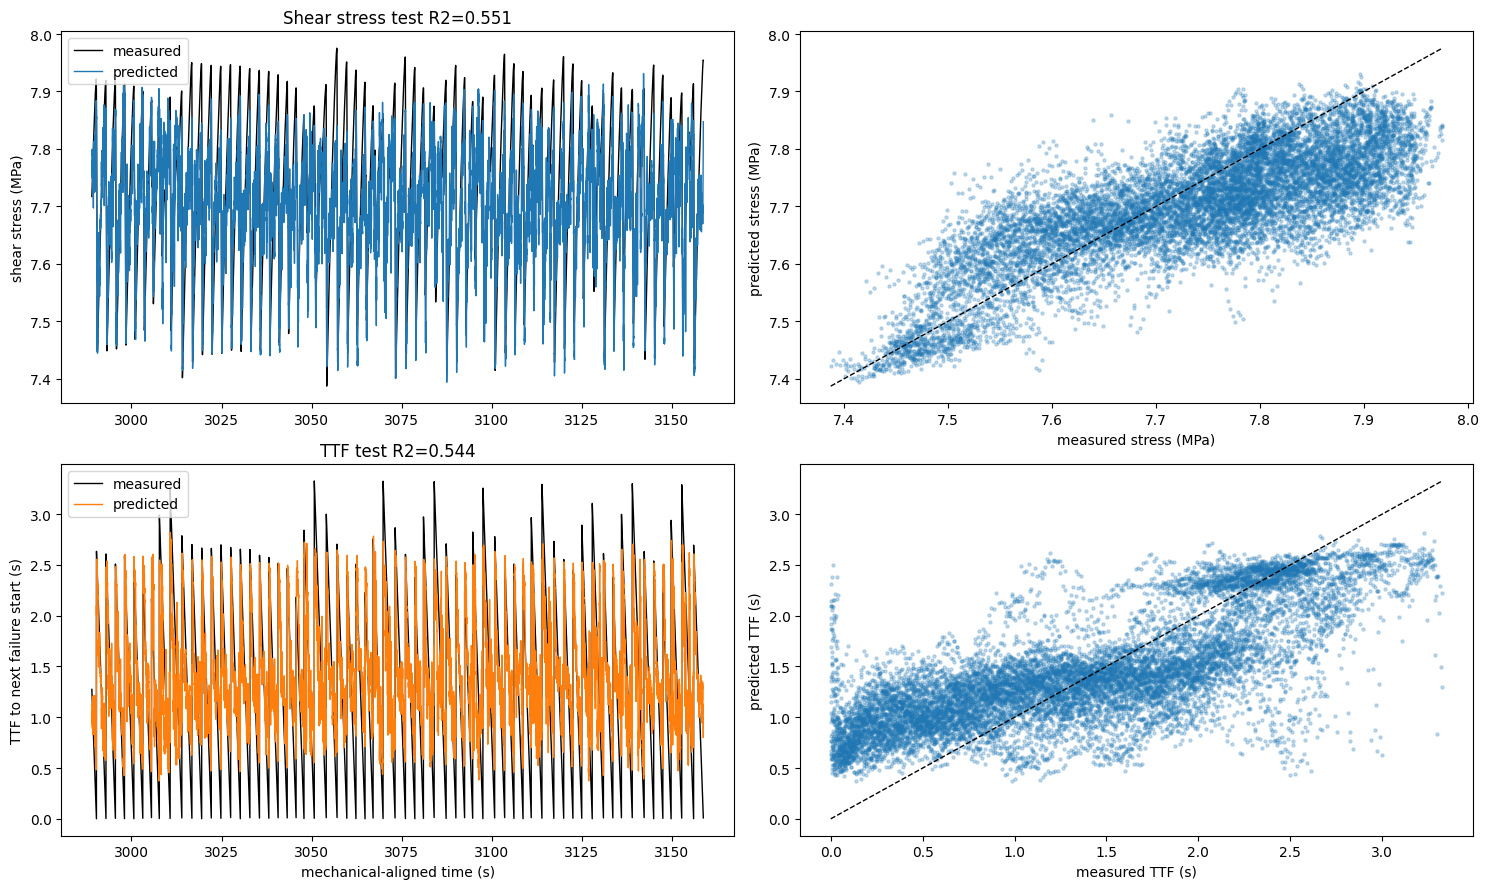

In [ ]:
def regression_metrics(y_true, y_pred):
    return {
        'r2': float(r2_score(y_true, y_pred)),
        'mae': float(mean_absolute_error(y_true, y_pred)),
        'rmse': float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }


ttf_metrics = regression_metrics(y_ttf_test, ttf_prediction)
stress_metrics = regression_metrics(
    y_stress_test,
    stress_prediction,
)
metrics_table = pd.DataFrame([
    {
        'target': 'ttf_to_failure_start_s',
        'training_cv_r2': ttf_cv_r2,
        **ttf_metrics,
    },
    {
        'target': 'mean_shear_stress_mpa',
        'training_cv_r2': stress_cv_r2,
        **stress_metrics,
    },
])
display(metrics_table)

test_time = sample_time[test_indices]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

axes[0, 0].plot(test_time, y_stress_test, color='black', lw=1, label='measured')
axes[0, 0].plot(test_time, stress_prediction, color='tab:blue', lw=1, label='predicted')
axes[0, 0].set_title(f'Shear stress test R2={stress_metrics["r2"]:.3f}')
axes[0, 0].set_ylabel('shear stress (MPa)')
axes[0, 0].legend()

axes[1, 0].plot(test_time, y_ttf_test, color='black', lw=1, label='measured')
axes[1, 0].plot(test_time, ttf_prediction, color='tab:orange', lw=1, label='predicted')
axes[1, 0].set_title(f'TTF test R2={ttf_metrics["r2"]:.3f}')
axes[1, 0].set_xlabel('mechanical-aligned time (s)')
axes[1, 0].set_ylabel('TTF to next failure start (s)')
axes[1, 0].legend()

axes[0, 1].scatter(y_stress_test, stress_prediction, s=5, alpha=0.25)
stress_limits = [
    min(y_stress_test.min(), stress_prediction.min()),
    max(y_stress_test.max(), stress_prediction.max()),
]
axes[0, 1].plot(stress_limits, stress_limits, 'k--', lw=1)
axes[0, 1].set_xlabel('measured stress (MPa)')
axes[0, 1].set_ylabel('predicted stress (MPa)')

axes[1, 1].scatter(y_ttf_test, ttf_prediction, s=5, alpha=0.25)
ttf_limits = [
    min(y_ttf_test.min(), ttf_prediction.min()),
    max(y_ttf_test.max(), ttf_prediction.max()),
]
axes[1, 1].plot(ttf_limits, ttf_limits, 'k--', lw=1)
axes[1, 1].set_xlabel('measured TTF (s)')
axes[1, 1].set_ylabel('predicted TTF (s)')

fig.tight_layout()
plt.show()


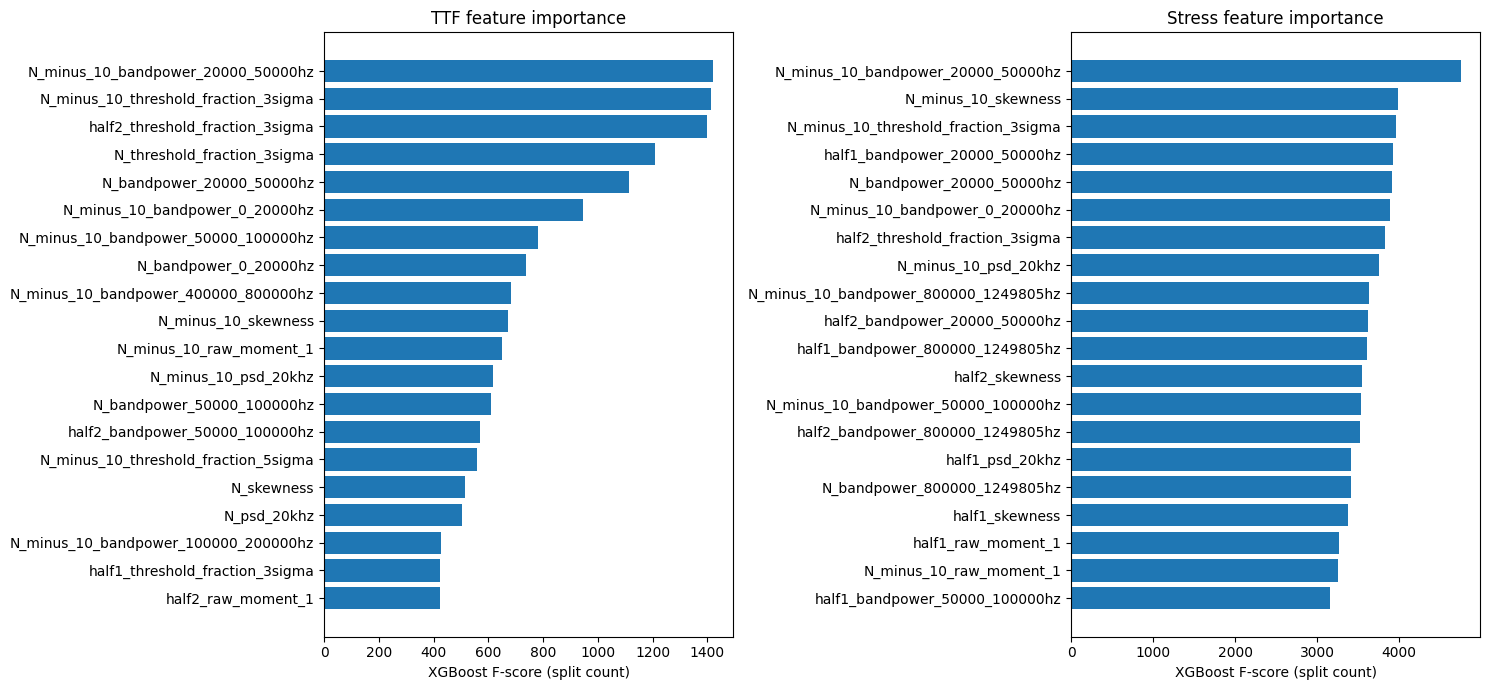

,target,feature,f_score_split_count
0,TTF,N_minus_10_bandpower_20000_50000hz,1422.0
1,TTF,N_minus_10_threshold_fraction_3sigma,1413.0
2,TTF,half2_threshold_fraction_3sigma,1399.0
3,TTF,N_threshold_fraction_3sigma,1210.0
4,TTF,N_bandpower_20000_50000hz,1113.0
5,TTF,N_minus_10_bandpower_0_20000hz,947.0
6,TTF,N_minus_10_bandpower_50000_100000hz,780.0
7,TTF,N_bandpower_0_20000hz,738.0
8,TTF,N_minus_10_bandpower_400000_800000hz,684.0
9,TTF,N_minus_10_skewness,670.0


,target,feature,f_score_split_count
0,shear_stress,N_minus_10_bandpower_20000_50000hz,4751.0
1,shear_stress,N_minus_10_skewness,3984.0
2,shear_stress,N_minus_10_threshold_fraction_3sigma,3961.0
3,shear_stress,half1_bandpower_20000_50000hz,3922.0
4,shear_stress,N_bandpower_20000_50000hz,3912.0
5,shear_stress,N_minus_10_bandpower_0_20000hz,3889.0
6,shear_stress,half2_threshold_fraction_3sigma,3828.0
7,shear_stress,N_minus_10_psd_20khz,3761.0
8,shear_stress,N_minus_10_bandpower_800000_1249805hz,3640.0
9,shear_stress,half2_bandpower_20000_50000hz,3622.0


In [ ]:
def feature_importance_frame(model, selected_columns, target_name):
    # Hulbert et al. report the gradient-boosted-tree F-score:
    # the number of times a feature is selected for a split.
    split_counts = model.get_booster().get_score(
        importance_type='weight'
    )
    frame = pd.DataFrame({
        'target': target_name,
        'feature': selected_columns,
        'f_score_split_count': [
            float(split_counts.get(f'f{index}', 0.0))
            for index in range(len(selected_columns))
        ],
    })
    return frame.sort_values(
        'f_score_split_count',
        ascending=False,
    ).reset_index(drop=True)


ttf_importance = feature_importance_frame(
    ttf_model,
    ttf_feature_columns,
    'TTF',
)
stress_importance = feature_importance_frame(
    stress_model,
    stress_feature_columns,
    'shear_stress',
)
importance_table = pd.concat(
    [ttf_importance, stress_importance],
    ignore_index=True,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for axis, frame, title in [
    (axes[0], ttf_importance.head(20), 'TTF feature importance'),
    (axes[1], stress_importance.head(20), 'Stress feature importance'),
]:
    plot_frame = frame.iloc[::-1]
    axis.barh(
        plot_frame['feature'],
        plot_frame['f_score_split_count'],
    )
    axis.set_title(title)
    axis.set_xlabel('XGBoost F-score (split count)')
fig.tight_layout()
plt.show()

display(ttf_importance.head(20))
display(stress_importance.head(20))


## 16. Save the reproducible 06 database, models, predictions and metadata


In [ ]:
sensor_tag = f'sensor{SENSOR_ZERO_BASED}'
method_tag = 'hulbert2019_all_76_features_no_rfe'

DATABASE_CSV = OUT_DIR / (
    f'06_ml_database_p5986_{sensor_tag}_{method_tag}.csv.gz'
)
PREDICTIONS_CSV = OUT_DIR / (
    f'06_test_predictions_p5986_{sensor_tag}_{method_tag}.csv.gz'
)
METRICS_CSV = OUT_DIR / (
    f'06_metrics_p5986_{sensor_tag}_{method_tag}.csv'
)
IMPORTANCE_CSV = OUT_DIR / (
    f'06_feature_importance_p5986_{sensor_tag}_{method_tag}.csv'
)
TTF_MODEL_FILE = OUT_DIR / (
    f'06_xgboost_TTF_p5986_{sensor_tag}_{method_tag}.joblib'
)
STRESS_MODEL_FILE = OUT_DIR / (
    f'06_xgboost_shear_stress_p5986_{sensor_tag}_{method_tag}.joblib'
)
METADATA_JSON = OUT_DIR / (
    f'06_metadata_p5986_{sensor_tag}_{method_tag}.json'
)

test_database = database.iloc[test_indices].copy()
test_database['ttf_prediction_raw_s'] = ttf_prediction
test_database['ttf_prediction_nonnegative_s'] = (
    ttf_prediction_nonnegative
)
test_database['shear_stress_prediction_mpa'] = stress_prediction

database.to_csv(DATABASE_CSV, index=False, compression='gzip')
test_database.to_csv(
    PREDICTIONS_CSV,
    index=False,
    compression='gzip',
)
metrics_table.to_csv(METRICS_CSV, index=False)
importance_table.to_csv(IMPORTANCE_CSV, index=False)
joblib.dump(ttf_model, TTF_MODEL_FILE)
joblib.dump(stress_model, STRESS_MODEL_FILE)

metadata = {
    'experiment': 'p5986',
    'run': 'run1',
    'notebook': '06',
    'method_reference': (
        'Hulbert et al. (2019), Similarity of fast and slow '
        'earthquakes illuminated by machine learning'
    ),
    'publication_specified': {
        'window_fraction_of_mean_cycle': 0.05,
        'overlap_fraction': 0.90,
        'two_contiguous_subwindows': True,
        'feature_families': [
            'raw moments 1-4',
            'variance',
            'skewness',
            'kurtosis',
            'threshold precursors',
            'Fourier-band power',
        ],
        'supplement_disclosed_contexts': ['N', 'N-10'],
        'train_test_split': (
            'first contiguous 50% training; '
            'second contiguous 50% testing'
        ),
        'feature_selection': 'recursive feature elimination',
        'cross_validation': '5-fold on training data',
        'hyperparameter_optimization': 'EGO / gp_minimize',
        'model': 'XGBoost gradient boosted regression trees',
    },
    'publication_does_not_numerically_specify': [
        'precursor threshold values',
        'complete frequency-band edges',
        'exact RFE estimator and stopping count',
        'exact time coordinate assigned to each window TTF label',
    ],
    'p5986_adaptations': {
        'threshold_calibration': (
            'absolute deviation from robust centre; '
            'centre and MAD scale estimated from first training-half files only'
        ),
        'threshold_sigma_multipliers': (
            THRESHOLD_SIGMA_MULTIPLIERS.tolist()
        ),
        'robust_center_adc': robust_center,
        'robust_sigma_adc': robust_sigma,
        'amplitude_thresholds_adc': amplitude_thresholds.tolist(),
        'frequency_bands_hz': [
            [float(low), float(high)]
            for low, high in frequency_bands_hz
        ],
        'ps20_actual_fft_bin_hz': ps20_actual_hz,
        'spectral_gap_policy': (
            'periodogram computed independently per stored 512-sample waveform; '
            'band powers averaged within each interval'
        ),
        'minimum_coverage_fraction': MIN_COVERAGE_FRACTION,
        'rejected_feature_rows': rejected_coverage,
        'feature_selection_for_this_run': (
            'none; all available 76 features were used'
        ),
    },
    'sensor_zero_based': SENSOR_ZERO_BASED,
    'hardware_channel': int(channels2save[SENSOR_ZERO_BASED]),
    'window_seconds': WINDOW_SECONDS,
    'step_seconds': STEP_SECONDS,
    'mean_cycle_s': mean_cycle_s,
    'median_cycle_s': median_cycle_s,
    'feature_columns_available': feature_columns,
    'feature_selection': 'none',
    'ttf_model_feature_columns': ttf_feature_columns,
    'stress_model_feature_columns': stress_feature_columns,
    'targets': {
        'ttf': (
            'next Notebook-03 shear-stress failure pick '
            'minus acoustic window centre time'
        ),
        'shear_stress': (
            'mean mechanical shear stress in the same full current window'
        ),
    },
    'coseismic_masking': False,
    'failure_spanning_windows_retained': True,
    'train_fraction': TRAIN_FRACTION,
    'boundary_purge': False,
    'ttf_best_params': ttf_params,
    'stress_best_params': stress_params,
    'ttf_training_cv_r2': ttf_cv_r2,
    'stress_training_cv_r2': stress_cv_r2,
    'ttf_test_metrics': ttf_metrics,
    'stress_test_metrics': stress_metrics,
    'train_time_range_s': [
        float(sample_time[train_indices[0]]),
        float(sample_time[train_indices[-1]]),
    ],
    'test_time_range_s': [
        float(sample_time[test_indices[0]]),
        float(sample_time[test_indices[-1]]),
    ],
}
METADATA_JSON.write_text(
    json.dumps(metadata, indent=2),
    encoding='utf-8',
)

print('saved:')
for path in [
    DATABASE_CSV,
    PREDICTIONS_CSV,
    METRICS_CSV,
    IMPORTANCE_CSV,
    TTF_MODEL_FILE,
    STRESS_MODEL_FILE,
    METADATA_JSON,
]:
    print(' -', path)


saved:
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_ml_database_p5986_sensor9_hulbert2019_all_76_features_no_rfe.csv.gz
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_test_predictions_p5986_sensor9_hulbert2019_all_76_features_no_rfe.csv.gz
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_metrics_p5986_sensor9_hulbert2019_all_76_features_no_rfe.csv
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_feature_importance_p5986_sensor9_hulbert2019_all_76_features_no_rfe.csv
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_xgboost_TTF_p5986_sensor9_hulbert2019_all_76_features_no_rfe.joblib
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_xgboost_shear_stress_p5986_sensor9_hulbert2019_all_76_features_no_rfe.joblib
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_metadata_p5986_sensor9_hulbert2019_all_76_features_no_rfe.json



Train rows: 49556
Test rows: 12390
Number of model features: 8

TTF hyperparameters loaded from:
/content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_xgboost_TTF_p5986_sensor9_hulbert2019_all_76_features_no_rfe.joblib

Shear-stress hyperparameters loaded from:
/content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_xgboost_shear_stress_p5986_sensor9_hulbert2019_all_76_features_no_rfe.joblib


,target,prediction,r2,mae,rmse
0,TTF,raw,0.337176,0.549978,0.663129
1,TTF,clipped at zero,0.337176,0.549978,0.663129
2,shear stress,raw,0.306916,0.088896,0.110049


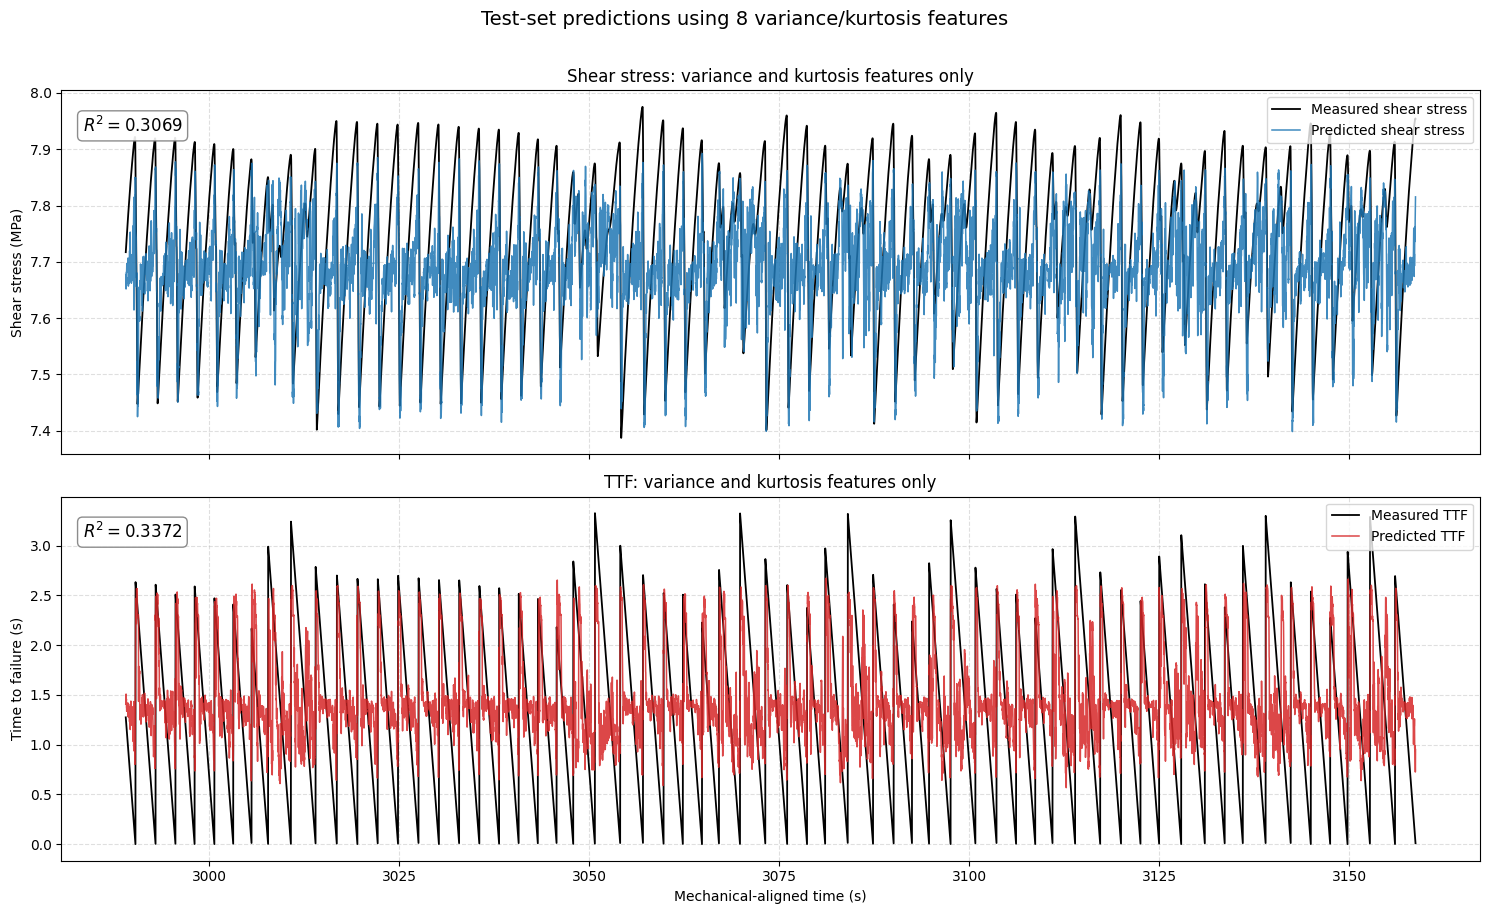

In [ ]:
# Chronological 80/20 split

TRAIN_FRACTION = 0.80

split_index = int(np.floor(
    len(database) * TRAIN_FRACTION
))

train_database = database.iloc[:split_index].copy()
test_database = database.iloc[split_index:].copy()


# Both targets use the same eight features.
X_train_vk = train_database[
    selected_vk_features
].to_numpy(dtype=np.float64)

X_test_vk = test_database[
    selected_vk_features
].to_numpy(dtype=np.float64)


# TTF labels
y_ttf_train = train_database[
    'ttf_to_failure_start_s'
].to_numpy(dtype=np.float64)

y_ttf_test = test_database[
    'ttf_to_failure_start_s'
].to_numpy(dtype=np.float64)


# Shear-stress labels
y_stress_train = train_database[
    'mean_shear_stress_mpa'
].to_numpy(dtype=np.float64)

y_stress_test = test_database[
    'mean_shear_stress_mpa'
].to_numpy(dtype=np.float64)


# Time coordinate for plotting
test_time = test_database[
    'window_center_s'
].to_numpy(dtype=np.float64)


print('\nTrain rows:', len(train_database))
print('Test rows:', len(test_database))
print('Number of model features:', X_train_vk.shape[1])

assert X_train_vk.shape[1] == 8
assert X_test_vk.shape[1] == 8


# Find and load previously trained reference models

def find_reference_model(
    preferred_paths,
    required_keywords,
    target_name,
):

    for path in preferred_paths:
        if path.exists():
            return path

    compatible_files = []

    for path in OUT_DIR.glob('*.joblib'):
        filename_lower = path.name.lower()

        if all(
            keyword.lower() in filename_lower
            for keyword in required_keywords
        ):
            compatible_files.append(path)

    if not compatible_files:
        raise FileNotFoundError(
            f'No saved {target_name} XGBoost model was found '
            f'in {OUT_DIR}.'
        )

    # Use the most recently modified compatible model.
    compatible_files.sort(
        key=lambda path: path.stat().st_mtime,
        reverse=True,
    )

    return compatible_files[0]


# TTF reference model
ttf_reference_file = find_reference_model(
    preferred_paths=[
        OUT_DIR / (
            '06_xgboost_TTF_p5986_sensor9_'
            'hulbert2019_all_76_features_no_rfe.joblib'
        ),
        OUT_DIR / (
            '06_xgboost_TTF_p5986_sensor9_'
            'hulbert2019_full_feature_families.joblib'
        ),
    ],
    required_keywords=[
        'xgboost',
        'ttf',
        'sensor9',
    ],
    target_name='TTF',
)


# Shear-stress reference model
stress_reference_file = find_reference_model(
    preferred_paths=[
        OUT_DIR / (
            '06_xgboost_shear_stress_p5986_sensor9_'
            'hulbert2019_all_76_features_no_rfe.joblib'
        ),
        OUT_DIR / (
            '06_xgboost_shear_stress_p5986_sensor9_'
            'hulbert2019_full_feature_families.joblib'
        ),
        OUT_DIR / (
            '06_xgboost_stress_p5986_sensor9_'
            'hulbert2019_all_76_features_no_rfe.joblib'
        ),
        OUT_DIR / (
            '06_xgboost_stress_p5986_sensor9_'
            'hulbert2019_full_feature_families.joblib'
        ),
    ],
    required_keywords=[
        'xgboost',
        'stress',
        'sensor9',
    ],
    target_name='shear-stress',
)


reference_ttf_model = joblib.load(
    ttf_reference_file
)

reference_stress_model = joblib.load(
    stress_reference_file
)


# clone() retains model hyperparameters but removes fitted trees.
ttf_vk_model = clone(reference_ttf_model)
stress_vk_model = clone(reference_stress_model)


print('\nTTF hyperparameters loaded from:')
print(ttf_reference_file)

print('\nShear-stress hyperparameters loaded from:')
print(stress_reference_file)


# Train each model once — no Bayesian optimization

ttf_vk_model.fit(
    X_train_vk,
    y_ttf_train,
)

stress_vk_model.fit(
    X_train_vk,
    y_stress_train,
)


ttf_prediction_raw = ttf_vk_model.predict(
    X_test_vk
)

# TTF cannot physically be negative.
ttf_prediction_nonnegative = np.maximum(
    ttf_prediction_raw,
    0.0,
)

stress_prediction = stress_vk_model.predict(
    X_test_vk
)


# Calculate metrics

def calculate_metrics(y_true, y_prediction):
    return {
        'r2': r2_score(
            y_true,
            y_prediction,
        ),
        'mae': mean_absolute_error(
            y_true,
            y_prediction,
        ),
        'rmse': np.sqrt(
            mean_squared_error(
                y_true,
                y_prediction,
            )
        ),
    }


ttf_metrics_raw = calculate_metrics(
    y_ttf_test,
    ttf_prediction_raw,
)

ttf_metrics_nonnegative = calculate_metrics(
    y_ttf_test,
    ttf_prediction_nonnegative,
)

stress_metrics = calculate_metrics(
    y_stress_test,
    stress_prediction,
)


comparison = pd.DataFrame([
    {
        'target': 'TTF',
        'prediction': 'raw',
        **ttf_metrics_raw,
    },
    {
        'target': 'TTF',
        'prediction': 'clipped at zero',
        **ttf_metrics_nonnegative,
    },
    {
        'target': 'shear stress',
        'prediction': 'raw',
        **stress_metrics,
    },
])

display(comparison)


# 7. Plot measured and predicted values

fig, axes = plt.subplots(
    2,
    1,
    figsize=(15, 9),
    sharex=True,
)


# ---- Shear-stress overlay ----

axes[0].plot(
    test_time,
    y_stress_test,
    color='black',
    linewidth=1.3,
    label='Measured shear stress',
)

axes[0].plot(
    test_time,
    stress_prediction,
    color='tab:blue',
    linewidth=1.1,
    alpha=0.85,
    label='Predicted shear stress',
)

axes[0].set_ylabel('Shear stress (MPa)')

axes[0].set_title(
    'Shear stress: variance and kurtosis features only'
)

axes[0].legend(
    loc='upper right'
)

axes[0].grid(
    True,
    linestyle='--',
    alpha=0.4,
)

axes[0].text(
    0.015,
    0.93,
    rf'$R^2 = {stress_metrics["r2"]:.4f}$',
    transform=axes[0].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox={
        'boxstyle': 'round',
        'facecolor': 'white',
        'edgecolor': 'gray',
        'alpha': 0.9,
    },
)


# ---- TTF overlay ----

axes[1].plot(
    test_time,
    y_ttf_test,
    color='black',
    linewidth=1.3,
    label='Measured TTF',
)

axes[1].plot(
    test_time,
    ttf_prediction_nonnegative,
    color='tab:red',
    linewidth=1.1,
    alpha=0.85,
    label='Predicted TTF',
)

axes[1].set_xlabel(
    'Mechanical-aligned time (s)'
)

axes[1].set_ylabel(
    'Time to failure (s)'
)

axes[1].set_title(
    'TTF: variance and kurtosis features only'
)

axes[1].legend(
    loc='upper right'
)

axes[1].grid(
    True,
    linestyle='--',
    alpha=0.4,
)

axes[1].text(
    0.015,
    0.93,
    rf'$R^2 = {ttf_metrics_nonnegative["r2"]:.4f}$',
    transform=axes[1].transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox={
        'boxstyle': 'round',
        'facecolor': 'white',
        'edgecolor': 'gray',
        'alpha': 0.9,
    },
)


fig.suptitle(
    'Test-set predictions using 8 variance/kurtosis features',
    fontsize=14,
    y=1.01,
)

fig.tight_layout()
plt.show()